# Figure 7A and 7B of Higgins et al. (2017), _beta-VAE_

The required comparison uses beta = 4 and beta = 1, with three seeds each. A beta = 16 run supports the assignment's question about increasing beta.

By default, this notebook displays the committed figures and measurements without loading data or weights. Set `RUN_TRAINING = True` to train the models and regenerate the figures. If you already have the weights, set `RECOMPUTE_ANALYSIS = True` to rerun the analysis only. Weights and datasets are excluded from Git.


In [ ]:
import json
import subprocess
import sys

from IPython.display import Image, display

RUN_TRAINING = False
RECOMPUTE_ANALYSIS = False
if RUN_TRAINING:
    subprocess.run(["bash", "run_all.sh"], check=True)

## Figure 7A/7B (seed 0) and what every used latent encodes

For every latent with learnt variance below 0.5: the fraction of the variance of its mean explained by one factor alone. `rot|shape` is rotation within a shape; `pos(x,y)` treats position as one two-dimensional factor.
The figure is drawn for seed 0; seeds 1 and 2 are only analyzed.



beta=4 seed=0: 5 informative latents, total KL 11.06 nats, reconstruction at z=mu: 62.9 nats and 24.8 wrong pixels per image
  latent  var    KL   | shape scale rot|shape  posX  posY  pos(x,y)
  z8     0.002 3.28  | 0.00  0.00   0.00     0.82  0.13   0.96
  z7     0.005 2.99  | 0.00  0.02   0.00     0.06  0.69   0.86
  z9     0.009 2.44  | 0.07  0.30   0.00     0.18  0.18   0.53
  z10    0.091 1.43  | 0.00  0.00   0.28     0.01  0.13   0.26
  z3     0.184 0.92  | 0.01  0.00   0.50     0.00  0.00   0.01
  z10: periods of the rotation response per full turn (square, oval, heart) = [4, 2, 2], amplitudes = [0.07, 1.24, 0.34]
  z3: periods of the rotation response per full turn (square, oval, heart) = [4, 2, 2], amplitudes = [0.04, 1.54, 0.39]
  mean over latents of the largest single-factor fraction: 0.52 (x and y separate), 0.63 (position as one factor)

beta=1 seed=0: 5 informative latents, total KL 16.36 nats, reconstruction at z=mu: 47.6 nats and 17.7 wrong pixels per image
  latent  

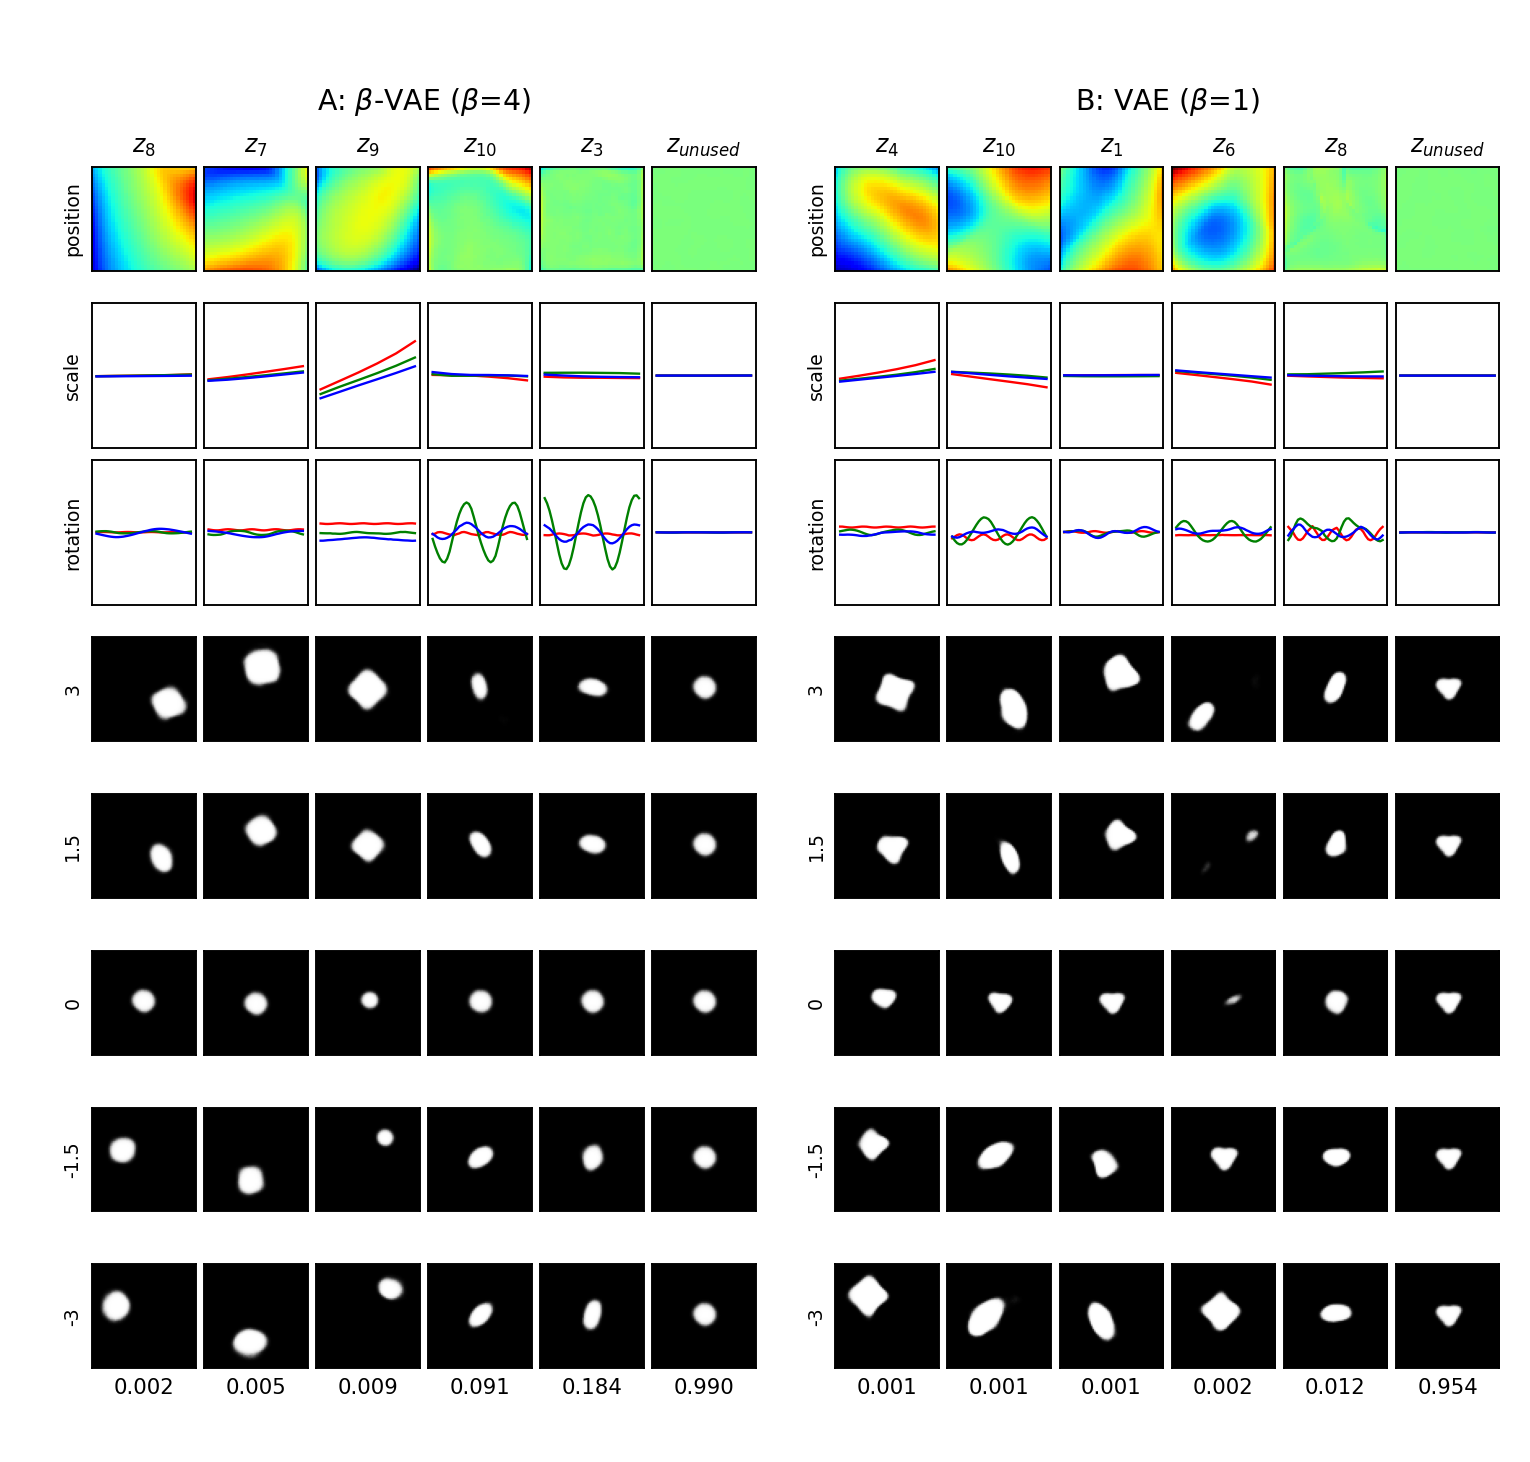

In [ ]:
command = [sys.executable, "analyze.py", "--betas", "4,1", "--seeds", "0,1,2"]
if not RECOMPUTE_ANALYSIS:
    command.append("--summary-only")
subprocess.run(command, check=True)
display(Image("figures/fig7ab_reproduced.png"))

## A larger beta: one model with $\beta=16$


In [ ]:
command = [sys.executable, "analyze.py", "--betas", "16", "--seeds", "0", "--out", ""]
if not RECOMPUTE_ANALYSIS:
    command.append("--summary-only")
subprocess.run(command, check=True)


beta=16 seed=0: 3 informative latents, total KL 5.92 nats, reconstruction at z=mu: 108.6 nats and 46.2 wrong pixels per image
  latent  var    KL   | shape scale rot|shape  posX  posY  pos(x,y)
  z2     0.003 3.48  | 0.00  0.00   0.00     0.78  0.05   0.96
  z10    0.036 1.83  | 0.02  0.12   0.00     0.27  0.03   0.40
  z4     0.306 0.61  | 0.00  0.21   0.00     0.28  0.06   0.41
  mean over latents of the largest single-factor fraction: 0.44 (x and y separate), 0.59 (position as one factor)


CompletedProcess(args=['/usr/local/bin/python3', 'analyze.py', '--betas', '16', '--seeds', '0', '--out', '', '--summary-only'], returncode=0)

## All models


In [ ]:
with open("figures/fig7_summary.json") as f:
    summary = json.load(f)
print(
    f"{'model':12s} {'used':>4s} {'KL':>7s} {'-log p(x|z)':>12s} {'wrong px':>9s}   single-factor fraction (x,y separate / joint)"
)
for key in sorted(summary, key=lambda k: (float(k.split("_")[0][4:]), k)):
    m = summary[key]
    print(
        f"{key:12s} {m['n_informative']:4d} {m['kl_total']:7.2f} {m['recon_nll']:12.1f} {m['wrong_pixels']:9.1f}   "
        f"{m['purity_separate']:.2f} / {m['purity_joint_pos']:.2f}"
    )

model        used      KL  -log p(x|z)  wrong px   single-factor fraction (x,y separate / joint)
beta1_s0        5   16.36         47.6      17.7   0.27 / 0.65
beta1_s1        5   16.54         44.6      16.5   0.49 / 0.61
beta1_s2        5   15.26         57.5      21.8   0.64 / 0.83
beta4_s0        5   11.06         62.9      24.8   0.52 / 0.63
beta4_s1        5   11.02         62.1      24.8   0.54 / 0.61
beta4_s2        4    9.93         78.6      34.1   0.76 / 0.82
beta16_s0       3    5.92        108.6      46.2   0.44 / 0.59


## Reconstructions: what a larger beta costs


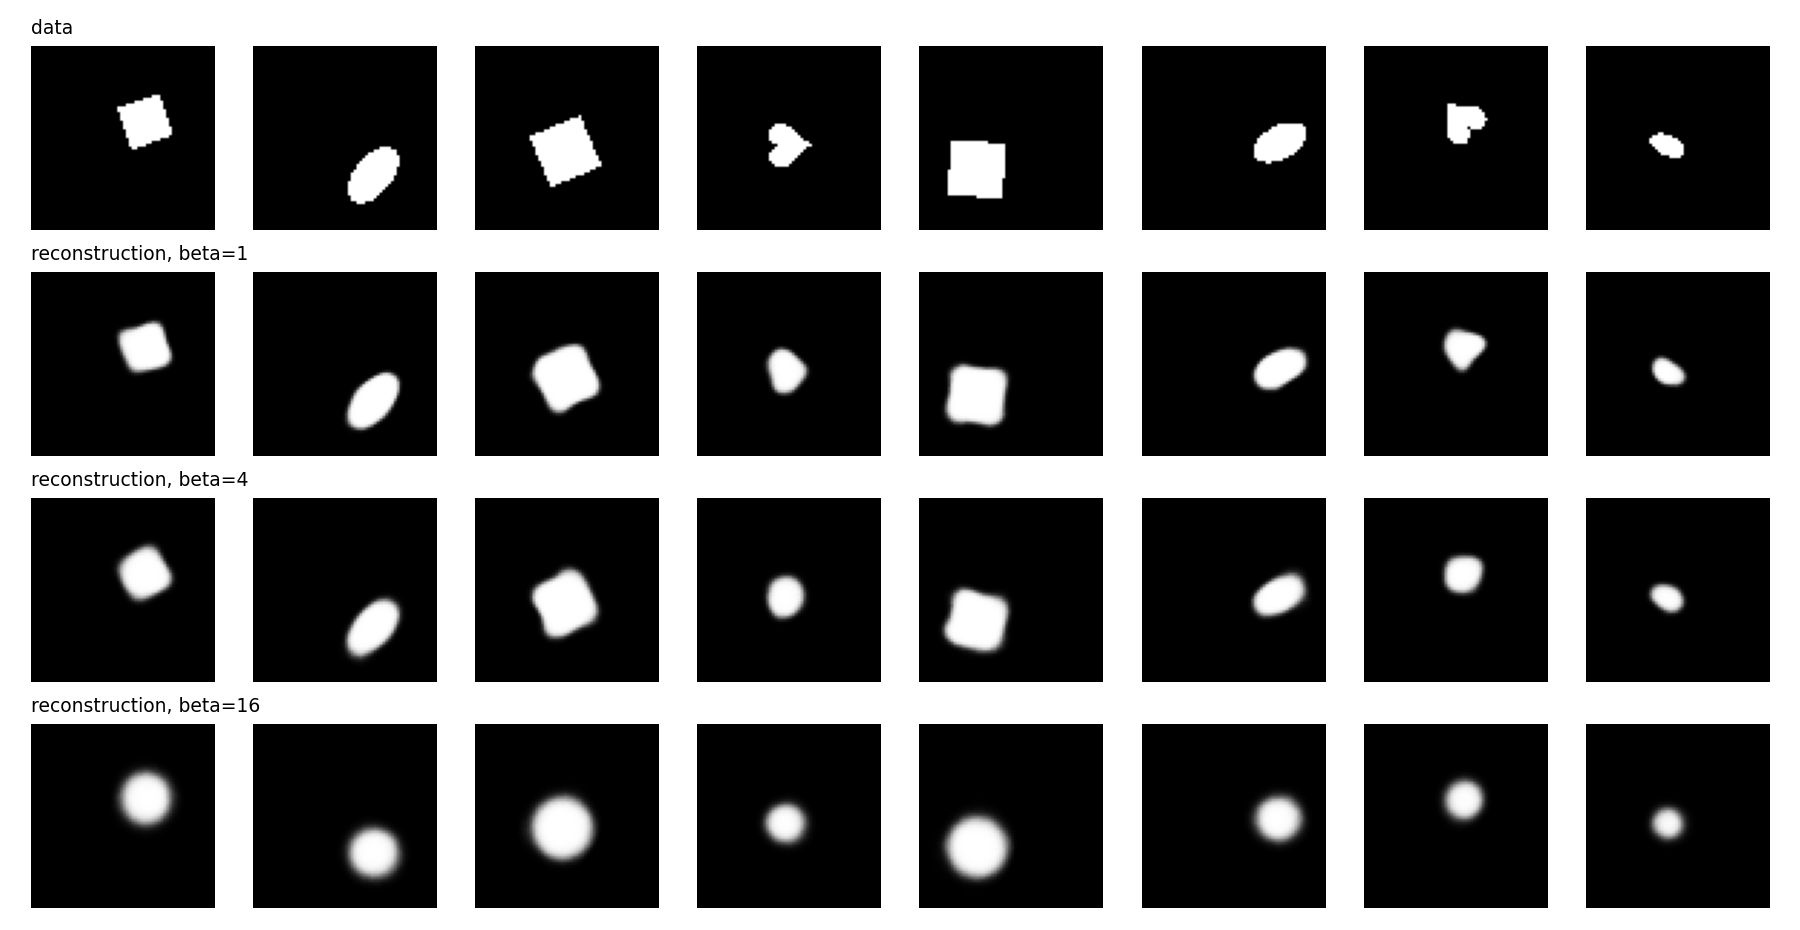

In [ ]:
if RECOMPUTE_ANALYSIS:
    subprocess.run([sys.executable, "reconstruct.py"], check=True)
display(Image("figures/reconstructions.png"))